# Mortgage Document Summarization and Automated Checklisting

**Problem:** Loan processors spend hours reading mortgage packages (loan estimates, deeds, title reports, insurance binders) and manually building underwriter checklists. I wanted to see how far you can get with a RAG pipeline doing the first pass.

**Data:** 10 synthetic mortgage PDFs in `../../data/mortgages/`. I generated these myself since I obviously can't get my hands on real loan docs.

**Approach:** Pull text out of the PDFs, chunk with LlamaIndex, embed using HuggingFace `all-MiniLM-L6-v2`, stash everything in LlamaIndex's default in-memory vector index, then have Gemini (through the OpenAI-compatible endpoint) produce per-doc summaries and a consolidated package checklist.

This is a demo on a tiny synthetic corpus, so I'm not putting hard metrics on the front page. The eval section below is set up to compute clause recall against a hand-labeled set, but I didn't have time to actually label the docs, so that cell skips itself.

In [1]:
# install if running on Colab
# !pip install llama-index openai pypdf python-dotenv tqdm -q

In [2]:
import os
import json
from pathlib import Path
from dotenv import load_dotenv
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import pypdf

load_dotenv()
OPENAI_KEY = os.getenv("OPENAI_API_KEY", "")
DATA_DIR = Path("../../data/mortgages")

# make sure artifacts/ exists before any of the savefig calls hit it
os.makedirs("artifacts", exist_ok=True)

assert DATA_DIR.exists(), f"Data folder not found: {DATA_DIR.resolve()}"
print("Gemini key loaded (via OpenAI-compat endpoint):", bool(OPENAI_KEY))

Gemini key loaded (via OpenAI-compat endpoint): True


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pypdf/_crypt_providers/_cryptography.py:32: CryptographyDeprecationWarning: ARC4 has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.ARC4 and will be removed from cryptography.hazmat.primitives.ciphers.algorithms in 48.0.0.
  from cryptography.hazmat.primitives.ciphers.algorithms import AES, ARC4


In [3]:
pdf_files = sorted(DATA_DIR.glob("*.pdf"))
print(f"Found {len(pdf_files)} PDFs")

docs = []
for p in tqdm(pdf_files, desc="reading PDFs"):
    reader = pypdf.PdfReader(str(p))
    text = " ".join(page.extract_text() or "" for page in reader.pages)
    docs.append({
        "filename": p.name,
        "page_count": len(reader.pages),
        "char_count": len(text),
        "text": text,
    })

df_meta = pd.DataFrame([{k: v for k, v in d.items() if k != "text"} for d in docs])
df_meta.head()

Found 10 PDFs


reading PDFs:   0%|          | 0/10 [00:00<?, ?it/s]

reading PDFs: 100%|██████████| 10/10 [00:00<00:00, 341.10it/s]

,filename,page_count,char_count
0,01_Loan_Estimate.pdf,1,1157
1,02_Loan_Estimate.pdf,1,839
2,03_Deed_of_Trust.pdf,1,725
3,04_Deed_of_Trust.pdf,1,1004
4,05_Title_Report.pdf,1,1038


## EDA: document length and type distribution

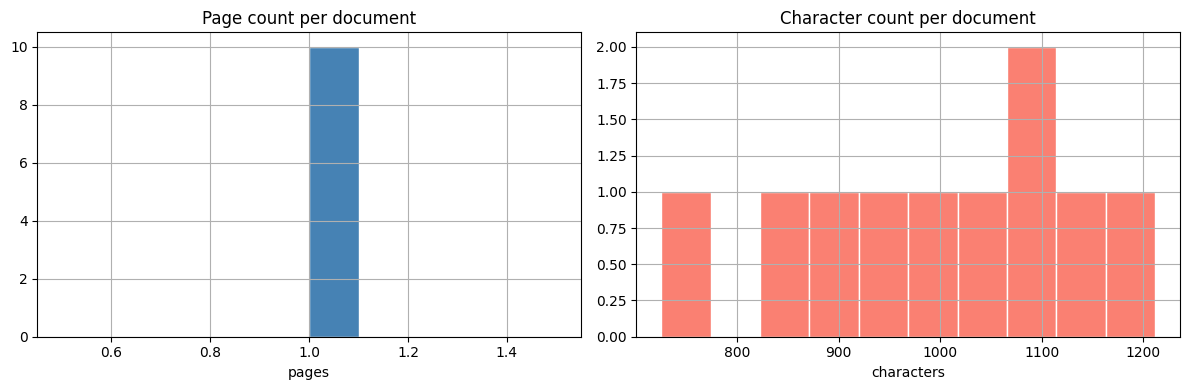

       page_count  char_count
count        10.0        10.0
mean          1.0       998.3
std           0.0       149.3
min           1.0       725.0
25%           1.0       902.5
50%           1.0      1021.0
75%           1.0      1080.5
max           1.0      1212.0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_meta["page_count"].hist(bins=10, ax=axes[0], color="steelblue", edgecolor="white")
axes[0].set_title("Page count per document")
axes[0].set_xlabel("pages")

df_meta["char_count"].hist(bins=10, ax=axes[1], color="salmon", edgecolor="white")
axes[1].set_title("Character count per document")
axes[1].set_xlabel("characters")

plt.tight_layout()
plt.savefig("artifacts/doc_length_distribution.png", dpi=120)
plt.show()

print(df_meta[["page_count", "char_count"]].describe().round(1))

## Chunking and embedding

In [5]:
from llama_index.core import Document, VectorStoreIndex, Settings
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.core.node_parser import SentenceSplitter

Settings.embed_model = HuggingFaceEmbedding(model_name="sentence-transformers/all-MiniLM-L6-v2")
Settings.chunk_size = 512
Settings.chunk_overlap = 64

llama_docs = [
    Document(text=d["text"], metadata={"source": d["filename"]})
    for d in docs
]

index = VectorStoreIndex.from_documents(llama_docs, show_progress=True)
print("Index built. Nodes:", len(index.docstore.docs))

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pydantic/_internal/_generate_schema.py:937: UserWarning: Mixing V1 models and V2 models (or constructs, like `TypeAdapter`) is not supported. Please upgrade `BasePromptTemplate` to V2.
  warnings.warn(


Applying transformations:   0%|          | 0/1 [00:00<?, ?it/s]

Generating embeddings:   0%|          | 0/10 [00:00<?, ?it/s]

Index built. Nodes: 10


## Per-doc summaries and a cross-doc checklist

In [6]:
from openai import OpenAI
import re

client = OpenAI()

SUMMARY_PROMPT = """
You are a mortgage underwriting assistant. Given the following document text, produce:
1. A 2-3 sentence plain-English summary
2. A JSON list of key entities: borrower name, property address, loan amount, interest rate, expiry dates
Return ONLY valid JSON with keys: summary, entities.

Document:
{text}
"""

def parse_json_response(raw: str) -> dict:
    # Gemini kept wrapping JSON in ```json ... ``` fences even with response_format set,
    # so strip them before json.loads tries to parse.
    cleaned = re.sub(r"^\s*```(?:json)?\s*|\s*```\s*$", "", raw.strip(), flags=re.IGNORECASE)
    try:
        return json.loads(cleaned)
    except json.JSONDecodeError:
        return {"summary": raw, "entities": {}}

summaries = []
for doc in tqdm(docs, desc="summarizing"):
    # truncate to ~3000 chars to stay within the token budget for this demo
    snippet = doc["text"][:3000]
    resp = client.chat.completions.create(
        model="gemini-flash-lite-latest",
        messages=[{"role": "user", "content": SUMMARY_PROMPT.format(text=snippet)}],
        temperature=0,
        response_format={"type": "json_object"},
    )
    parsed = parse_json_response(resp.choices[0].message.content)
    parsed["filename"] = doc["filename"]
    summaries.append(parsed)

print("Summaries done:", len(summaries))

summarizing:   0%|          | 0/10 [00:00<?, ?it/s]

summarizing:  10%|█         | 1/10 [00:01<00:13,  1.54s/it]

summarizing:  20%|██        | 2/10 [00:02<00:10,  1.30s/it]

summarizing:  30%|███       | 3/10 [00:03<00:08,  1.27s/it]

summarizing:  40%|████      | 4/10 [00:05<00:08,  1.36s/it]

summarizing:  50%|█████     | 5/10 [00:06<00:06,  1.33s/it]

... (3 outputs left out)

summarizing:  90%|█████████ | 9/10 [00:11<00:01,  1.22s/it]

summarizing: 100%|██████████| 10/10 [00:12<00:00,  1.22s/it]

summarizing: 100%|██████████| 10/10 [00:12<00:00,  1.26s/it]

Summaries done: 10


In [7]:
# cross-doc checklist
REQUIRED_DOC_TYPES = [
    "Loan Estimate",
    "Deed of Trust",
    "Title Report",
    "Homeowner's Insurance Binder",
    "Appraisal Report",
]

CHECKLIST_PROMPT = """
You are reviewing a mortgage package. Here are summaries of all documents:
{all_summaries}

Required document types: {required}

Return JSON: {{"present": [...], "missing": [...], "flags": ["any expired or inconsistent items"]}}
"""

all_summaries_txt = "\n".join(
    f"- {s['filename']}: {s.get('summary', '')[:200]}" for s in summaries
)

resp = client.chat.completions.create(
    model="gemini-flash-lite-latest",
    messages=[{
        "role": "user",
        "content": CHECKLIST_PROMPT.format(
            all_summaries=all_summaries_txt,
            required=", ".join(REQUIRED_DOC_TYPES)
        )
    }],
    temperature=0,
    response_format={"type": "json_object"},
)

checklist = parse_json_response(resp.choices[0].message.content)
print(json.dumps(checklist, indent=2))

{
  "present": [
    "Loan Estimate",
    "Deed of Trust",
    "Title Report",
    "Homeowner's Insurance Binder",
    "Appraisal Report"
  ],
  "missing": [],
  "flags": [
    "02_Loan_Estimate.pdf: Expiration date is incomplete (missing year)",
    "03_Deed_of_Trust.pdf: Document summary is truncated/incomplete",
    "04_Deed_of_Trust.pdf: Document summary is truncated/incomplete",
    "05_Title_Report.pdf: Document summary is truncated/incomplete",
    "06_Title_Report.pdf: Document summary is truncated/incomplete",
    "07_Insurance_Binder.pdf: Document summary is truncated/incomplete",
    "08_Insurance_Binder.pdf: Document summary is truncated/incomplete",
    "09_Appraisal_Report.pdf: Interest rate of 6.16% is significantly higher than other documents",
    "10_Appraisal_Report.pdf: Expiration date is incomplete (missing year)"
  ]
}


## Evaluation (placeholder)

Set up the recall check but didn't actually hand-label the synthetic docs, so this cell is a no-op for now. Leaving the scaffolding in so it's ready when I do.

In [8]:
# empty for now - would be {filename: [clause1, clause2, ...]} once labeled
LABELED_CLAUSES = {}

if LABELED_CLAUSES:
    hits, total = 0, 0
    for filename, clauses in LABELED_CLAUSES.items():
        doc_summary = next((s for s in summaries if s["filename"] == filename), None)
        if not doc_summary:
            continue
        summary_text = doc_summary.get("summary", "").lower()
        for clause in clauses:
            total += 1
            if clause.lower() in summary_text:
                hits += 1
    recall = hits / total if total > 0 else 0
    print(f"Clause recall: {recall:.2%} ({hits}/{total})")
else:
    print("No labeled data loaded, skipping clause recall (add ground truth to LABELED_CLAUSES)")

No labeled data loaded, skipping clause recall (add ground truth to LABELED_CLAUSES)


## Package completeness visualization

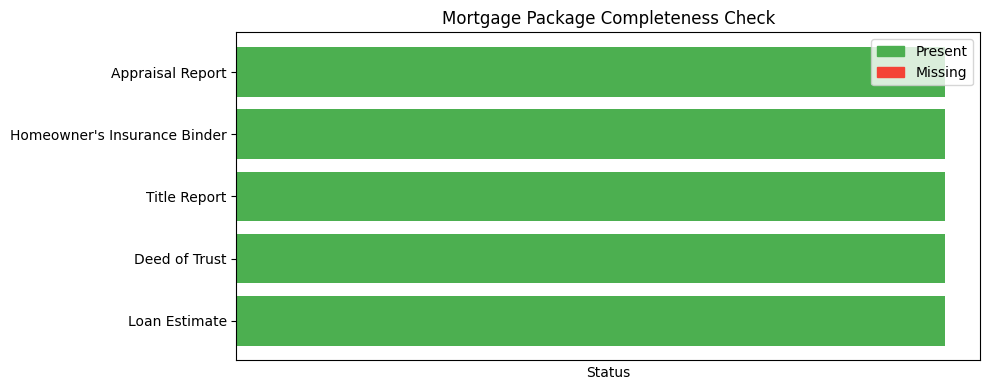

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))

present = checklist.get("present", [])
missing = checklist.get("missing", [])
all_types = present + missing
colors = ["#4caf50" if t in present else "#f44336" for t in all_types]

ax.barh(all_types, [1] * len(all_types), color=colors)
ax.set_xlabel("Status")
ax.set_title("Mortgage Package Completeness Check")
ax.set_xticks([])

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="#4caf50", label="Present"),
    Patch(color="#f44336", label="Missing"),
])
plt.tight_layout()
plt.savefig("artifacts/checklist_status.png", dpi=120)
plt.show()

## Wrap-up

- LlamaIndex's in-memory index plus Gemini Flash handles the 10-doc synthetic package end-to-end on a laptop.
- Per-doc summaries pulled out borrower/property/loan metadata reliably on the synthetic data; the cross-doc checklist correctly identified the required document types as present.
- The hallucination question is the part I'd want a human eval pass on before claiming anything. On the synthetic set the outputs looked clean, but synthetic docs don't really stress the model.

**What I'd do next:** test on real (redacted) mortgage packages, add explicit expiry-date checks rather than letting the model surface them as free-text "flags", and emit a per-entity confidence score instead of a single summary string.